<h1 style="color:#C2185B">Final Evaluation</h1>

<h2 style="color:#C2185B">Owner</h2>

<h3 style="color:#C2185B">Goal</h3>

Compare Isolation Forest and Local Outlier Factor on all 590,540 transactions, using the scores and
experiment logs saved by 03 and 04

<h4 style="color:#C2185B">Outline</h4>

- **[I. Configuration & Setup](#config-setup)**
- **[II. Load Saved Results](#load)**
- **[III. Isolation Forest](#isolation-forest)**
  1. [Experiments run](#if-experiments)
  2. [How the final model was chosen](#if-choice)
  3. [Detection quality](#if-quality)
  4. [Score distribution](#if-distribution)
  5. [Parameter sweeps](#if-sweeps)
- **[IV. Local Outlier Factor](#lof)**
  1. [Experiments run on the 25,000-row sample](#lof-sample)
  2. [Experiments run on the full dataset](#lof-full)
  3. [How the final model was chosen](#lof-choice)
  4. [Detection quality](#lof-quality)
  5. [Score distribution](#lof-distribution)
  6. [Parameter sweep](#lof-sweeps)
- **[V. Comparison](#comparison)**
  1. [Final models side by side](#metrics-table)
  2. [ROC and precision-recall curves](#curves)
  3. [Confusion matrices](#confusion)
  4. [Fraud caught at each review budget](#budget)
  5. [Fraud caught by each method](#catch-breakdown)
- **[VI. UMAP Projection](#umap)**
  1. [Fraud in the projection](#map-fraud)
  2. [What each method flagged](#map-flagged)
  3. [Fraud caught by each method](#map-caught)
- **[VII. Runtime](#runtime)**
- **[VIII. Research Questions](#research-questions)**
  1. [RQ1: detection without labels](#rq1)
  2. [RQ2: comparing the two methods](#rq2)
  3. [RQ3: computational cost](#rq3)
- **[IX. Limitations](#limitations)**
- **[X. Sanity Check](#sanity-check)**
- **[Appendix: Combining the Two Rankings](#appendix)**

<a id="config-setup"></a>
<h1 style="color:#C2185B">I. Configuration & Setup</h1>

In [1]:
# Configuration & Setup

# Import the libraries used in this notebook
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr, gaussian_kde
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve, confusion_matrix)

# Define base directory for the project: walk up from the current working
# directory until a file that only exists at the repo root is found.
PROJECT_MARKERS = ('.git', 'requirements.txt')


# Define function to find the project root
def find_project_root(start_dir=None, markers=PROJECT_MARKERS):
    current = os.path.abspath(start_dir or os.getcwd())
    while True:
        if any(os.path.exists(os.path.join(current, m)) for m in markers):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise FileNotFoundError(f"Could not locate project root (looked for {markers})")
        current = parent


BASE_DIR = find_project_root()

# Define the paths this notebook reads from
CLEANED_DATA_DIR = os.path.join(BASE_DIR, 'data', 'cleaned')
IF_DIR = os.path.join(BASE_DIR, 'results', 'isolation_forest')
LOF_DIR = os.path.join(BASE_DIR, 'results', 'lof_reference')
LOF_SWEEP_DIR = os.path.join(BASE_DIR, 'results', 'lof')
UMAP_DIR = os.path.join(BASE_DIR, 'results', 'umap')
LADDER_PATH = os.path.join(BASE_DIR, '00_nafisat', 'results', 'runtime_ladder.csv')

# Define where this notebook writes its figures and tables
RESULTS_DIR = os.path.join(BASE_DIR, 'results', 'final_evaluation')
os.makedirs(RESULTS_DIR, exist_ok=True)

# Print
print(f"Project root directory: {BASE_DIR}")
print(f"Results directory: {RESULTS_DIR}")

Project root directory: c:\Users\Nafis\ProjectsHub_WiM\unsupervised-fraud-detection-the-outliers
Results directory: c:\Users\Nafis\ProjectsHub_WiM\unsupervised-fraud-detection-the-outliers\results\final_evaluation


In [2]:
# Settings used throughout the notebook

# The review budget: a reviewer opens the top 3.5% of a ranking. This matches
# the fraud rate, so precision and recall come out on the same scale.
REVIEW_BUDGET_FRAC = 0.035

# How many rows the LOF parameter sweep in 04 was run on
LOF_SWEEP_ROWS = 25_000

# Colours. Blue is Isolation Forest, pink is LOF, purple is both (the two
# mixed), grey is neither. These mean the same thing in every figure.
C_IF = '#2a78d6'
C_LOF = '#d55181'
C_BOTH = '#7d3c98'
C_NEITHER = '#8a857c'
C_INK = '#2b2926'
C_SOFT = '#716d66'
C_GRID = '#ecebe7'

# Darker versions for text.
C_IF_TEXT = '#1d5aa6'
C_LOF_TEXT = '#a8355a'
C_BOTH_TEXT = '#5e2d73'
C_NEITHER_TEXT = '#6b665e'

# Colour ramps built from those colours
CMAP_IF = LinearSegmentedColormap.from_list('if', ['#ffffff', C_IF])
CMAP_LOF = LinearSegmentedColormap.from_list('lof', ['#ffffff', C_LOF])

# Show full tables
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 180)

# Print
print(f"Review budget: top {REVIEW_BUDGET_FRAC:.1%} of each ranking")

Review budget: top 3.5% of each ranking


In [3]:
# Helper functions

# Define function to apply the shared look to a set of axes
def style_plot(ax, title=None, xlabel=None, ylabel=None):
    """Apply the shared look to one set of axes."""
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=9.5, color=C_SOFT)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=9.5, color=C_SOFT)
    ax.grid(True, color=C_GRID, linewidth=0.7)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('bottom', 'left'):
        ax.spines[side].set_color('#cfccc6')
    ax.tick_params(colors=C_SOFT, labelsize=8.5)
    if title:
        ax.set_title(title, fontsize=12, fontweight='bold', color=C_INK, pad=9)
    return ax


# Define function to put x ticks on the values actually tested
def log_ticks(ax, values):
    """Label a log axis with the values tested, rather than powers of ten."""
    values = sorted(set(int(v) for v in values))
    ax.set_xscale('log')
    ax.set_xticks(values)
    ax.set_xticklabels([f'{v:,}' for v in values], fontsize=8.5)
    ax.minorticks_off()
    return ax


# Define function to save a figure into the results directory
def save_fig(fig, name):
    """Save a figure into the results directory."""
    path = os.path.join(RESULTS_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print(f"Saved {name}")
    return path


# Define function to compute the metrics quoted throughout this notebook
def metrics_for(scores, truth, budget_frac=REVIEW_BUDGET_FRAC):
    """Return every metric quoted in this notebook, for one ranking."""
    budget = int(budget_frac * len(truth))
    flagged_idx = np.argsort(scores)[::-1][:budget]
    caught = int(truth[flagged_idx].sum())
    pr = average_precision_score(truth, scores)
    return {
        'roc_auc': roc_auc_score(truth, scores),
        'pr_auc': pr,
        'precision': caught / budget,
        'recall': caught / truth.sum(),
        'reviewed': budget,
        'frauds_found': caught,
    }


# Print
print("Helper functions defined")

Helper functions defined


<a id="load"></a>
<h1 style="color:#C2185B">II. Load Saved Results</h1>

In [4]:
# Load the label every method is evaluated against
label = pd.read_parquet(os.path.join(CLEANED_DATA_DIR, 'label.parquet'))['isFraud']
y = label.to_numpy()

# Record the size of the problem, used in most calculations below
N_ROWS = len(y)
N_FRAUD = int(y.sum())
BASE_RATE = y.mean()

# Load each method's saved anomaly scores, ordered to match the label
if_scores = (pd.read_csv(os.path.join(IF_DIR, 'anomaly_scores.csv'))
             .set_index('transaction_index')['anomaly_score']
             .loc[np.arange(N_ROWS)].to_numpy())
lof_scores = (pd.read_csv(os.path.join(LOF_DIR, 'anomaly_scores.csv'))
              .set_index('transaction_index')['anomaly_score']
              .loc[np.arange(N_ROWS)].to_numpy())

# Load the experiment log each notebook wrote
if_log = pd.read_csv(os.path.join(IF_DIR, 'experiment_log.csv'))
lof_full_log = pd.read_csv(os.path.join(LOF_DIR, 'experiment_log.csv'))
lof_sample_log = pd.read_csv(os.path.join(LOF_SWEEP_DIR, 'experiment_log.csv'))

# Pull out the configuration each method settled on
if_final = if_log[if_log['experiment'] == 'final'].iloc[-1]
lof_final = lof_full_log[lof_full_log['experiment'] == 'final'].iloc[-1]

# Work out which transactions each method puts in its top 3.5%.
REVIEW_BUDGET = int(REVIEW_BUDGET_FRAC * N_ROWS)
top_if = set(np.argsort(if_scores)[::-1][:REVIEW_BUDGET])
top_lof = set(np.argsort(lof_scores)[::-1][:REVIEW_BUDGET])

# Confirm both methods scored every transaction
assert len(if_scores) == len(lof_scores) == N_ROWS, "the two methods cover different rows"
assert np.isfinite(if_scores).all() and np.isfinite(lof_scores).all(), "a non-finite score"

# Print
print(f"Transactions: {N_ROWS:,}")
print(f"Fraud: {N_FRAUD:,} ({BASE_RATE * 100:.2f}%)")
print(f"Review budget: top {REVIEW_BUDGET:,} ({REVIEW_BUDGET_FRAC:.1%})")
print()
print(f"Isolation Forest: {len(if_log)} logged runs")
print(f"LOF on the {LOF_SWEEP_ROWS:,}-row sample: {len(lof_sample_log)} logged runs")
print(f"LOF on the full dataset: {len(lof_full_log)} logged runs")

Transactions: 590,540
Fraud: 20,663 (3.50%)
Review budget: top 20,668 (3.5%)

Isolation Forest: 16 logged runs
LOF on the 25,000-row sample: 11 logged runs
LOF on the full dataset: 2 logged runs


<a id="isolation-forest"></a>
<h1 style="color:#C2185B">III. Isolation Forest</h1>

<a id="if-experiments"></a>
<h2 style="color:#C2185B">1. Experiments run</h2>

In [5]:
# Build one table per parameter swept.
#
# Each sweep varies ONE parameter and holds the others at their defaults, so
# rows within a table are comparable to each other and rows across tables are
# not. Separate tables make that structure visible.
#
# All four carry the same columns, so a row can be read the same way wherever
# it appears. Every run was evaluated on all 590,540 transactions.
IF_COLUMNS = ['roc_auc', 'pr_auc', 'precision', 'recall', 'accuracy', 'runtime_seconds']


# Define function to pull one sweep out of the experiment log
def if_sweep(prefix, parameter):
    """Return the rows of one Isolation Forest sweep, sorted by the parameter."""
    rows = if_log[if_log['experiment'].str.startswith(prefix)].copy()
    rows = rows[[parameter] + IF_COLUMNS]

    # Force the swept parameter to a number.
    #
    # These columns hold 'auto' on the rows where the parameter was left at its
    # default, so pandas reads the whole column as text. Sorting it would then
    # be alphabetical, and arithmetic on it does something worse: '0.035' * 100
    # repeats the string a hundred times rather than giving 3.5.
    rows[parameter] = pd.to_numeric(rows[parameter], errors='coerce')
    rows = rows.dropna(subset=[parameter]).sort_values(parameter)
    return rows.reset_index(drop=True)


# The untuned default and the configuration finally used
if_reference = (if_log[if_log['experiment'].isin(['baseline', 'final'])]
                [['experiment', 'contamination', 'n_estimators', 'max_samples'] + IF_COLUMNS]
                .reset_index(drop=True))

# The three sweeps
if_trees = if_sweep('n_estimators_', 'n_estimators')
if_samples = if_sweep('max_samples_', 'max_samples')
if_contamination = if_sweep('contamination_', 'contamination')

# Save them for the report
for name, table in [('baseline_and_final', if_reference), ('n_estimators', if_trees),
                    ('max_samples', if_samples), ('contamination', if_contamination)]:
    table.to_csv(os.path.join(RESULTS_DIR, f'if_{name}.csv'), index=False)

# Print
print(f"Four tables built, all evaluated on {N_ROWS:,} transactions")

Four tables built, all evaluated on 590,540 transactions


In [6]:
# Display all four tables together, with nothing between them.
# PR-AUC is shaded in each, so the best run in a sweep is easy to find.
FMT = {c: '{:.4f}' for c in ['roc_auc', 'pr_auc', 'precision', 'recall', 'accuracy']}
FMT['runtime_seconds'] = '{:.1f}'

display(if_reference.style.hide(axis='index').format(FMT, na_rep='-')
        .set_caption('Isolation Forest: the untuned default, and the configuration used'))

display(if_trees.style.hide(axis='index').format(FMT, na_rep='-')
        .background_gradient(subset=['pr_auc'], cmap=CMAP_IF)
        .set_caption('n_estimators: how many trees in the forest'))

display(if_samples.style.hide(axis='index').format(FMT, na_rep='-')
        .background_gradient(subset=['pr_auc'], cmap=CMAP_IF)
        .set_caption('max_samples: how many rows build each tree'))

display(if_contamination.style.hide(axis='index').format(FMT, na_rep='-')
        .background_gradient(subset=['precision'], cmap=CMAP_IF)
        .background_gradient(subset=['recall'], cmap=CMAP_LOF)
        .set_caption('contamination: where the cut-off sits. ROC-AUC and PR-AUC '
                     'are identical on every row, because this parameter moves '
                     'the threshold and never the scores.'))

experiment,contamination,n_estimators,max_samples,roc_auc,pr_auc,precision,recall,accuracy,runtime_seconds
baseline,auto,100,auto,0.7573,0.1352,0.2339,0.2070,0.9485,7.3
final,0.05,100,512,0.7568,0.1379,0.2053,0.2934,0.9355,11.8


n_estimators,roc_auc,pr_auc,precision,recall,accuracy,runtime_seconds
50,0.7542,0.1306,0.2247,0.2247,0.9457,5.0
100,0.7573,0.1352,0.2263,0.2263,0.9459,5.7
200,0.7628,0.1359,0.2256,0.2257,0.9458,9.5
500,0.7648,0.1345,0.2238,0.2238,0.9457,12.2


max_samples,roc_auc,pr_auc,precision,recall,accuracy,runtime_seconds
128,0.7591,0.1284,0.2099,0.2099,0.9447,4.5
256,0.7573,0.1352,0.2263,0.2263,0.9459,5.3
512,0.7568,0.1379,0.2338,0.2339,0.9464,5.0
10000,0.7421,0.1160,0.2012,0.2013,0.9441,9.1
590540,0.7307,0.0992,0.1642,0.1643,0.9415,10.7


contamination,roc_auc,pr_auc,precision,recall,accuracy,runtime_seconds
0.010000,0.7573,0.1352,0.2636,0.0754,0.9603,15.0
0.020000,0.7573,0.1352,0.2533,0.1448,0.9551,15.9
0.035000,0.7573,0.1352,0.2263,0.2263,0.9458,14.2
0.050000,0.7573,0.1352,0.2028,0.2897,0.9353,15.2
0.100000,0.7573,0.1352,0.1506,0.4303,0.8951,13.0


- **Comment:** One table per parameter. Every run was scored the same way, so the rows can be read against each other.


<a id="if-choice"></a>
<h2 style="color:#C2185B">2. How the final model was chosen</h2>

In [7]:
# The final model is the single run with the highest PR-AUC, refit exactly.
if_measured = if_log[if_log['experiment'] != 'final'].dropna(subset=['pr_auc'])
if_best = if_measured.loc[if_measured['pr_auc'].idxmax()]
if_runner_up = if_measured.nlargest(2, 'pr_auc').iloc[-1]

# Print
print("Chosen by PR-AUC, over every configuration measured")
print(f"  winner        {if_best['experiment']}  (PR-AUC {if_best['pr_auc']:.4f})")
print(f"  runner-up     {if_runner_up['experiment']}  (PR-AUC {if_runner_up['pr_auc']:.4f})")
print(f"  gap           {if_best['pr_auc'] - if_runner_up['pr_auc']:.4f}")
print()
print(f"Final configuration: contamination={if_final['contamination']}, "
      f"n_estimators={int(if_final['n_estimators'])}, "
      f"max_samples={if_final['max_samples']}")

Chosen by PR-AUC, over every configuration measured
  winner        max_samples_512  (PR-AUC 0.1379)
  runner-up     n_estimators_200  (PR-AUC 0.1359)
  gap           0.0020

Final configuration: contamination=0.05, n_estimators=100, max_samples=512


- **Comment:** The final model is whichever run scored the best PR-AUC. Nothing was picked by hand.


<a id="if-quality"></a>
<h2 style="color:#C2185B">3. Detection quality</h2>

In [8]:
# Compute the metrics for Isolation Forest, on all 590,540 transactions
if_metrics = metrics_for(if_scores, y)

# Print
print(f"Isolation Forest, all {N_ROWS:,} transactions")
print(f"  ROC-AUC     {if_metrics['roc_auc']:.4f}   (random scores 0.5000)")
print(f"  PR-AUC      {if_metrics['pr_auc']:.4f}   (random scores {BASE_RATE:.4f})")
print()
print(f"  Reviewing the top {if_metrics['reviewed']:,} transactions:")
print(f"    frauds found  {if_metrics['frauds_found']:,}")
print(f"    precision     {if_metrics['precision'] * 100:.2f}%  of what is opened is fraud")
print(f"    recall        {if_metrics['recall'] * 100:.2f}%  of all fraud in the dataset")

# How much tuning bought, which is the context for the numbers above
if_base = if_log[if_log['experiment'] == 'baseline']
if len(if_base):
    b = if_base.iloc[-1]['pr_auc']
    print()
    print(f"  Untuned defaults scored PR-AUC {b:.4f}, so tuning gained "
          f"{(if_metrics['pr_auc'] - b) / b * 100:+.1f}%")

Isolation Forest, all 590,540 transactions
  ROC-AUC     0.7568   (random scores 0.5000)
  PR-AUC      0.1379   (random scores 0.0350)

  Reviewing the top 20,668 transactions:
    frauds found  4,833
    precision     23.38%  of what is opened is fraud
    recall        23.39%  of all fraud in the dataset

  Untuned defaults scored PR-AUC 0.1352, so tuning gained +2.0%


- **Comment:** Both scores beat random ranking. Precision and recall are read at a fixed review budget, so they can be compared with LOF later.


<a id="if-distribution"></a>
<h2 style="color:#C2185B">4. Score distribution</h2>

Saved if_score_distribution.png


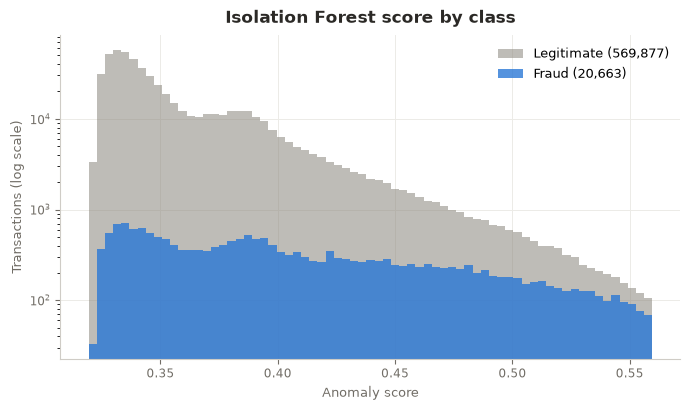

In [9]:
# Compare the score distribution of fraud against everything else.
# If the two overlap exactly, the method has found nothing.
fig, ax = plt.subplots(figsize=(8, 4.2))

# Clip the axis at the 99.5th percentile: the score has a long right tail that
# would otherwise squash the bulk of the data into one bar
bins = np.linspace(if_scores.min(), np.percentile(if_scores, 99.5), 70)

# Counts rather than density, so the rarity of fraud stays visible
ax.hist(if_scores[y == 0], bins=bins, color=C_NEITHER, alpha=0.55,
        label=f'Legitimate ({(y == 0).sum():,})')
ax.hist(if_scores[y == 1], bins=bins, color=C_IF, alpha=0.8,
        label=f'Fraud ({(y == 1).sum():,})')

# Log y-axis, because fraud is 3.5% of the data and would be invisible otherwise
ax.set_yscale('log')
style_plot(ax, 'Isolation Forest score by class', 'Anomaly score',
           'Transactions (log scale)')
ax.legend(frameon=False, fontsize=9)

save_fig(fig, 'if_score_distribution.png')
plt.show()

- **Comment:** Fraud scores higher on average, but the two distributions sit on top of each other. That overlap is the limit on how much can be caught.


<a id="if-sweeps"></a>
<h2 style="color:#C2185B">5. Parameter sweeps</h2>

Saved if_parameter_sweeps.png


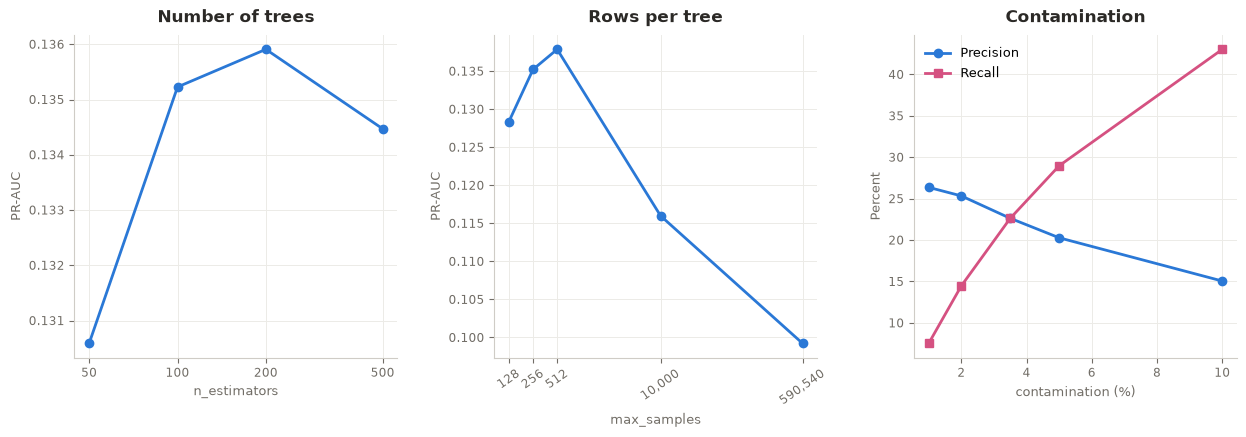

In [10]:
# The same three sweeps as the tables above, drawn
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={'wspace': 0.3})

# Number of trees
axes[0].plot(if_trees['n_estimators'], if_trees['pr_auc'], marker='o',
             color=C_IF, linewidth=2)
log_ticks(axes[0], if_trees['n_estimators'])
style_plot(axes[0], 'Number of trees', 'n_estimators', 'PR-AUC')

# Rows used to build each tree
axes[1].plot(if_samples['max_samples'], if_samples['pr_auc'],
             marker='o', color=C_IF, linewidth=2)
log_ticks(axes[1], if_samples['max_samples'])
axes[1].tick_params(axis='x', labelrotation=35)
style_plot(axes[1], 'Rows per tree', 'max_samples', 'PR-AUC')

# Contamination moves the threshold, so precision and recall are what change
axes[2].plot(if_contamination['contamination'] * 100,
             if_contamination['precision'] * 100, marker='o',
             color=C_IF, linewidth=2, label='Precision')
axes[2].plot(if_contamination['contamination'] * 100,
             if_contamination['recall'] * 100, marker='s',
             color=C_LOF, linewidth=2, label='Recall')
style_plot(axes[2], 'Contamination', 'contamination (%)', 'Percent')
axes[2].legend(frameon=False, fontsize=9)

save_fig(fig, 'if_parameter_sweeps.png')
plt.show()

# Contamination never changes the ranking, only the threshold, so confirm that
assert if_contamination['pr_auc'].nunique() == 1, "contamination changed PR-AUC"

- **Comment:** Trees and rows per tree change the ranking. Contamination does not: it only moves the cut-off, which trades precision against recall.


<a id="lof"></a>
<h1 style="color:#C2185B">IV. Local Outlier Factor</h1>

<a id="lof-sample"></a>
<h2 style="color:#C2185B">1. Experiments run on the 25,000-row sample</h2>

In [11]:
# The n_neighbors sweep from 04, run on a 25,000-row sample to keep it affordable.
#
# These rows are measured on 25,000 transactions and the
# full-data rows in the next section are measured on 590,540.
LOF_COLUMNS = ['roc_auc', 'pr_auc', 'precision', 'recall', 'accuracy', 'runtime_seconds']

lof_sample_table = (lof_sample_log[lof_sample_log['experiment'].str.startswith('n_neighbors_')]
                    [['n_neighbors'] + LOF_COLUMNS]
                    .sort_values('n_neighbors').reset_index(drop=True))

# Save it for the report
lof_sample_table.to_csv(os.path.join(RESULTS_DIR, 'lof_sample_sweep.csv'), index=False)

display(lof_sample_table.style.hide(axis='index').format(FMT, na_rep='-')
        .background_gradient(subset=['pr_auc'], cmap=CMAP_LOF)
        .set_caption(f'LOF n_neighbors sweep, fitted and scored on '
                     f'{LOF_SWEEP_ROWS:,} transactions'))

# Print
best_k = lof_sample_table.loc[lof_sample_table['pr_auc'].idxmax()]
print(f"Best PR-AUC {best_k['pr_auc']:.4f} at n_neighbors={int(best_k['n_neighbors'])}")
print(f"That is {int(best_k['n_neighbors']) / LOF_SWEEP_ROWS * 100:.2f}% of the sample")
print(f"Values tested: {sorted(lof_sample_table['n_neighbors'].astype(int).tolist())}")

n_neighbors,roc_auc,pr_auc,precision,recall,accuracy,runtime_seconds
10,0.6611,0.0569,0.0659,0.3182,0.8302,6.5
20,0.6865,0.0704,0.0750,0.3476,0.8386,7.1
35,0.7010,0.0827,0.0850,0.4039,0.8384,6.1
50,0.7074,0.0891,0.0883,0.4345,0.8350,6.1
80,0.7069,0.0897,0.0841,0.4480,0.8226,8.2
160,0.7047,0.0871,0.0818,0.4565,0.8147,8.4
320,0.7036,0.0859,0.0844,0.4663,0.8172,8.9
640,0.6940,0.0846,0.0778,0.4957,0.7914,10.1
1280,0.6702,0.0763,0.0625,0.5067,0.7355,13.9


Best PR-AUC 0.0897 at n_neighbors=80
That is 0.32% of the sample
Values tested: [10, 20, 35, 50, 80, 160, 320, 640, 1280]


- **Comment:** The best value falls inside the range tested, so the sweep was wide enough to find a peak rather than stop at an edge.


<a id="lof-full"></a>
<h2 style="color:#C2185B">2. Experiments run on the full dataset</h2>

In [12]:
# Fitting LOF on all 590,540 rows takes 98 minutes and scores worse, because
# n_neighbors has to scale with the size of the pool a transaction is compared
# against. Fitting on a reference set keeps that ratio right and scores every
# transaction against it.
lof_full_table = (lof_full_log[['experiment', 'n_neighbors', 'reference_rows',
                                'rows_scored'] + ['roc_auc', 'pr_auc', 'precision',
                                                  'recall', 'runtime_seconds']]
                  .reset_index(drop=True))

# Save it for the report
lof_full_table.to_csv(os.path.join(RESULTS_DIR, 'lof_full_runs.csv'), index=False)

display(lof_full_table.style.hide(axis='index').format(FMT, na_rep='-')
        .background_gradient(subset=['pr_auc'], cmap=CMAP_LOF)
        .set_caption(f'LOF on all {N_ROWS:,} transactions, scored against a '
                     f'50,000-row reference set'))

experiment,n_neighbors,reference_rows,rows_scored,roc_auc,pr_auc,precision,recall,runtime_seconds
baseline,20,50000,590540,0.6620,0.0622,0.0777,0.0777,414.6
final,160,50000,590540,0.7134,0.0910,0.1456,0.1457,509.2


- **Comment:** Fitting on every row is far slower and scores worse. The reference-set version is the one carried forward.


<a id="lof-choice"></a>
<h2 style="color:#C2185B">3. How the final model was chosen</h2>

In [13]:
# The sweep peaked at k=80 on 25,000 rows, which is 0.32% of the pool. The
# optimal k scales with the size of the set a transaction is compared against,
# so 0.32% of a 50,000-row reference is 160.
k_sweep = int(best_k['n_neighbors'])
k_final = int(lof_final['n_neighbors'])
reference_rows = int(lof_final['reference_rows'])

# Print
print("Chosen by PR-AUC on the sample, then scaled to the reference set")
print(f"  sweep winner      n_neighbors={k_sweep} on {LOF_SWEEP_ROWS:,} rows "
      f"({k_sweep / LOF_SWEEP_ROWS * 100:.2f}% of the pool)")
print(f"  carried over as   n_neighbors={k_final} on a {reference_rows:,}-row reference "
      f"({k_final / reference_rows * 100:.2f}% of the pool)")

# How much that choice bought over the untuned default
lof_base = lof_full_log[lof_full_log['experiment'] == 'baseline']
if len(lof_base):
    b = lof_base.iloc[-1]['pr_auc']
    f = lof_final['pr_auc']
    print()
    print(f"Untuned default (n_neighbors=20) scored PR-AUC {b:.4f}, tuned scores "
          f"{f:.4f} ({(f - b) / b * 100:+.1f}%)")


Chosen by PR-AUC on the sample, then scaled to the reference set
  sweep winner      n_neighbors=80 on 25,000 rows (0.32% of the pool)
  carried over as   n_neighbors=160 on a 50,000-row reference (0.32% of the pool)

Untuned default (n_neighbors=20) scored PR-AUC 0.0622, tuned scores 0.0910 (+46.1%)


- **Comment:** n_neighbors is held at a fixed share of the pool rather than a fixed number, because it has to grow with how many transactions it compares against.


<a id="lof-quality"></a>
<h2 style="color:#C2185B">4. Detection quality</h2>

In [14]:
# Compute the metrics for LOF, on all 590,540 transactions
lof_metrics = metrics_for(lof_scores, y)

# Print
print(f"Local Outlier Factor, all {N_ROWS:,} transactions")
print(f"  ROC-AUC     {lof_metrics['roc_auc']:.4f}   (random scores 0.5000)")
print(f"  PR-AUC      {lof_metrics['pr_auc']:.4f}   (random scores {BASE_RATE:.4f})")
print()
print(f"  Reviewing the top {lof_metrics['reviewed']:,} transactions:")
print(f"    frauds found  {lof_metrics['frauds_found']:,}")
print(f"    precision     {lof_metrics['precision'] * 100:.2f}%")
print(f"    recall        {lof_metrics['recall'] * 100:.2f}%")

Local Outlier Factor, all 590,540 transactions
  ROC-AUC     0.7134   (random scores 0.5000)
  PR-AUC      0.0910   (random scores 0.0350)

  Reviewing the top 20,668 transactions:
    frauds found  3,010
    precision     14.56%
    recall        14.57%


- **Comment:** LOF ranks fraud better than chance, and below Isolation Forest on the same data.


<a id="lof-distribution"></a>
<h2 style="color:#C2185B">5. Score distribution</h2>

Saved lof_score_distribution.png


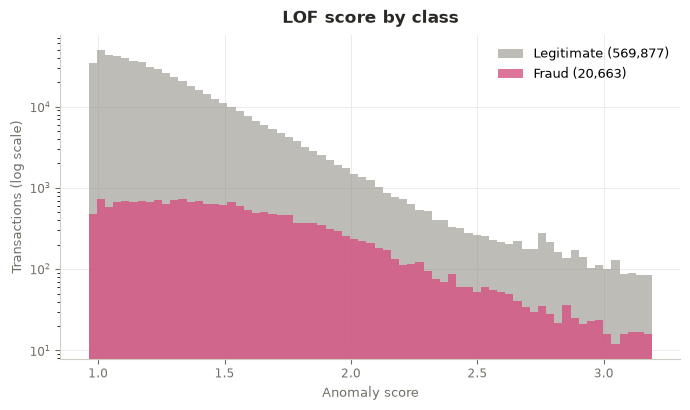

In [15]:
# LOF comparison
fig, ax = plt.subplots(figsize=(8, 4.2))

# Clip the long right tail
bins = np.linspace(lof_scores.min(), np.percentile(lof_scores, 99.5), 70)

# Counts rather than density
ax.hist(lof_scores[y == 0], bins=bins, color=C_NEITHER, alpha=0.55,
        label=f'Legitimate ({(y == 0).sum():,})')
ax.hist(lof_scores[y == 1], bins=bins, color=C_LOF, alpha=0.8,
        label=f'Fraud ({(y == 1).sum():,})')

# Log y-axis, same reason
ax.set_yscale('log')
style_plot(ax, 'LOF score by class', 'Anomaly score', 'Transactions (log scale)')
ax.legend(frameon=False, fontsize=9)

save_fig(fig, 'lof_score_distribution.png')
plt.show()

- **Comment:** Same shape as Isolation Forest: fraud sits a little higher, inside the same range as ordinary traffic.


<a id="lof-sweeps"></a>
<h2 style="color:#C2185B">6. Parameter sweep</h2>

Saved lof_parameter_sweep.png


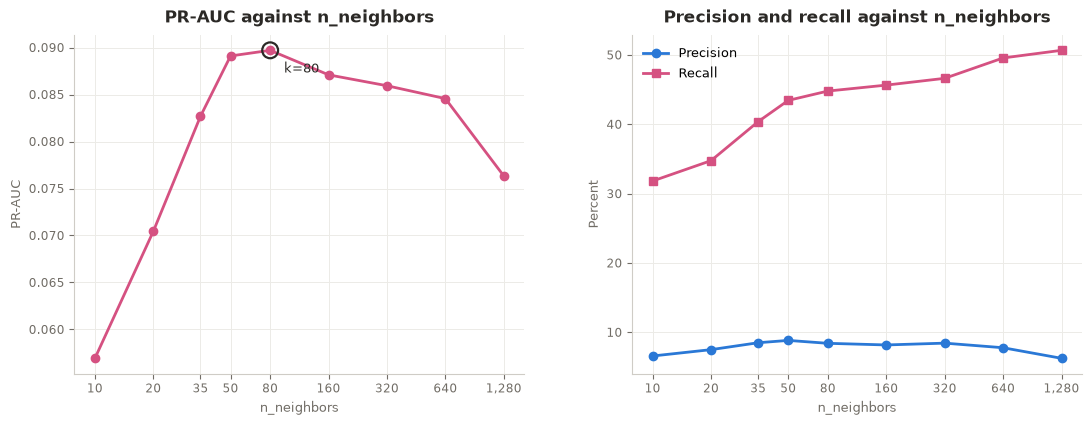

In [16]:
# The n_neighbors sweep, drawn. Run on the 25,000-row sample.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'wspace': 0.24})

# PR-AUC against k
axes[0].plot(lof_sample_table['n_neighbors'], lof_sample_table['pr_auc'],
             marker='o', color=C_LOF, linewidth=2)

# Ring the best value, so it is clear the peak is inside the range tested
axes[0].scatter([best_k['n_neighbors']], [best_k['pr_auc']], s=130, zorder=5,
                facecolor='none', edgecolor=C_INK, linewidth=1.6)
axes[0].annotate(f"k={int(best_k['n_neighbors'])}",
                 xy=(best_k['n_neighbors'], best_k['pr_auc']),
                 xytext=(10, -16), textcoords='offset points',
                 fontsize=9.5, color=C_INK)
log_ticks(axes[0], lof_sample_table['n_neighbors'])
style_plot(axes[0], 'PR-AUC against n_neighbors', 'n_neighbors', 'PR-AUC')

# Precision and recall move in opposite directions as k grows
axes[1].plot(lof_sample_table['n_neighbors'], lof_sample_table['precision'] * 100,
             marker='o', color=C_IF, linewidth=2, label='Precision')
axes[1].plot(lof_sample_table['n_neighbors'], lof_sample_table['recall'] * 100,
             marker='s', color=C_LOF, linewidth=2, label='Recall')
log_ticks(axes[1], lof_sample_table['n_neighbors'])
style_plot(axes[1], 'Precision and recall against n_neighbors', 'n_neighbors', 'Percent')
axes[1].legend(frameon=False, fontsize=9)

save_fig(fig, 'lof_parameter_sweep.png')
plt.show()


- **Comment:** Recall keeps rising with k, so choosing on recall alone would have picked the largest value and been wrong. PR-AUC is what the choice rests on.


<a id="comparison"></a>
<h1 style="color:#C2185B">V. Comparison</h1>

<a id="metrics-table"></a>
<h2 style="color:#C2185B">1. Final models side by side</h2>

In [17]:
# The two final models, with every metric spelled out.
#
# Each row is one measure. Each column is one method and both were evaluated on all 590,540 transaction
comparison = pd.DataFrame({
    'Isolation Forest': [
        f"{N_ROWS:,}",
        f"{if_metrics['roc_auc']:.4f}",
        f"{if_metrics['pr_auc']:.4f}",
        f"{if_metrics['pr_auc'] / BASE_RATE:.2f} times",
        f"{if_metrics['reviewed']:,}",
        f"{if_metrics['frauds_found']:,}",
        f"{if_metrics['precision'] * 100:.2f}%",
        f"{if_metrics['recall'] * 100:.2f}%",
        f"{float(if_final['runtime_seconds']):.1f} s",
    ],
    'Local Outlier Factor': [
        f"{N_ROWS:,}",
        f"{lof_metrics['roc_auc']:.4f}",
        f"{lof_metrics['pr_auc']:.4f}",
        f"{lof_metrics['pr_auc'] / BASE_RATE:.2f} times",
        f"{lof_metrics['reviewed']:,}",
        f"{lof_metrics['frauds_found']:,}",
        f"{lof_metrics['precision'] * 100:.2f}%",
        f"{lof_metrics['recall'] * 100:.2f}%",
        f"{float(lof_final['runtime_seconds']):.1f} s",
    ],
}, index=[
    'Transactions scored',
    'ROC-AUC',
    'PR-AUC',
    'PR-AUC against random guessing',
    f'Transactions reviewed (top {REVIEW_BUDGET_FRAC:.1%})',
    'Frauds found in those',
    'Precision: share of reviewed that is fraud',
    'Recall: share of all fraud that is found',
    'Time to fit and score',
])

# Save it for the report
comparison.to_csv(os.path.join(RESULTS_DIR, 'final_models_comparison.csv'))
display(comparison)

# Print
print(f"Random guessing scores ROC-AUC 0.5000 and PR-AUC {BASE_RATE:.4f}")

,Isolation Forest,Local Outlier Factor
Transactions scored,"590,540","590,540"
ROC-AUC,0.7568,0.7134
PR-AUC,0.1379,0.0910
PR-AUC against random guessing,3.94 times,2.60 times
Transactions reviewed (top 3.5%),"20,668","20,668"
Frauds found in those,"4,833","3,010"
Precision: share of reviewed that is fraud,23.38%,14.56%
Recall: share of all fraud that is found,23.39%,14.57%
Time to fit and score,11.8 s,509.2 s


Random guessing scores ROC-AUC 0.5000 and PR-AUC 0.0350


- **Comment:** Isolation Forest leads on every measure in this table.


<a id="curves"></a>
<h2 style="color:#C2185B">2. ROC and precision-recall curves</h2>

Saved roc_pr_curves.png


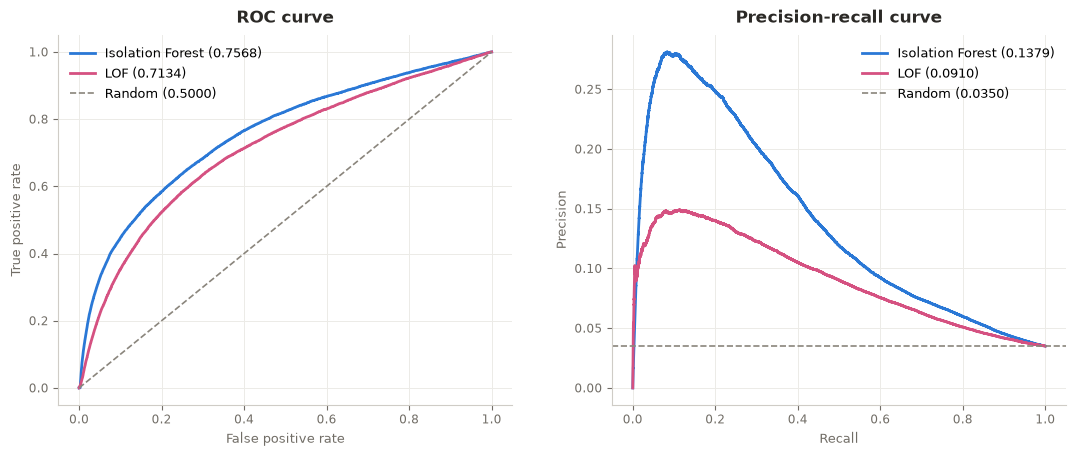

In [18]:
# Plot both curves for both methods
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 4.8),
                                    gridspec_kw={'wspace': 0.22})

for scores, name, colour, m in [(if_scores, 'Isolation Forest', C_IF, if_metrics),
                                (lof_scores, 'LOF', C_LOF, lof_metrics)]:
    fpr, tpr, _ = roc_curve(y, scores)
    ax_roc.plot(fpr, tpr, color=colour, linewidth=2,
                label=f"{name} ({m['roc_auc']:.4f})")
    precision, recall, _ = precision_recall_curve(y, scores)
    # Drop the last point: sklearn appends an artificial (recall=0, precision=1)
    # to close the curve, which would draw a spike to 1.0 at the left edge.
    ax_pr.plot(recall[:-1], precision[:-1], color=colour, linewidth=2,
               label=f"{name} ({m['pr_auc']:.4f})")

# Mark what random guessing achieves on each panel
ax_roc.plot([0, 1], [0, 1], '--', color=C_NEITHER, linewidth=1.2,
            label='Random (0.5000)')
ax_pr.axhline(BASE_RATE, linestyle='--', color=C_NEITHER, linewidth=1.2,
              label=f'Random ({BASE_RATE:.4f})')

style_plot(ax_roc, 'ROC curve', 'False positive rate', 'True positive rate')
style_plot(ax_pr, 'Precision-recall curve', 'Recall', 'Precision')
ax_roc.legend(frameon=False, fontsize=9)
ax_pr.legend(frameon=False, fontsize=9)

save_fig(fig, 'roc_pr_curves.png')
plt.show()

- **Comment:** ROC looks flattering because fraud is rare. The precision-recall curve is the honest view of a rare-event problem.


<a id="confusion"></a>
<h2 style="color:#C2185B">3. Confusion matrices</h2>

Saved confusion_matrices.png


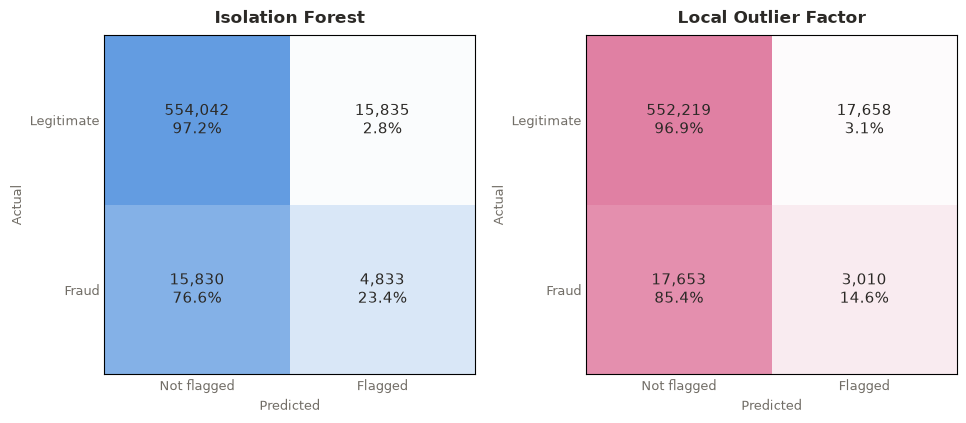

In [19]:
# A confusion matrix for each method, at the same 3.5% threshold
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={'wspace': 0.3})

for ax, flagged_set, name, cmap in [(axes[0], top_if, 'Isolation Forest', CMAP_IF),
                                    (axes[1], top_lof, 'Local Outlier Factor', CMAP_LOF)]:
    # Turn the flagged set into a 0/1 prediction for every transaction
    predicted = np.zeros(N_ROWS, dtype=int)
    predicted[list(flagged_set)] = 1
    cm = confusion_matrix(y, predicted)

    # Shade by the share of each ROW
    shaded = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(shaded, cmap=cmap, alpha=0.75, aspect='auto', vmin=0, vmax=1)

    # Write the count and the row percentage into each cell
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n{shaded[i, j] * 100:.1f}%",
                    ha='center', va='center', fontsize=11, color=C_INK)

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Not flagged', 'Flagged'], fontsize=9.5)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(['Legitimate', 'Fraud'], fontsize=9.5)
    ax.set_xlabel('Predicted', fontsize=9.5, color=C_SOFT)
    ax.set_ylabel('Actual', fontsize=9.5, color=C_SOFT)
    ax.set_title(name, fontsize=12, fontweight='bold', color=C_INK, pad=9)
    ax.grid(False)
    ax.tick_params(colors=C_SOFT, length=0)

save_fig(fig, 'confusion_matrices.png')
plt.show()

- **Comment:** Percentages run across each row, so the four of them add to 200%, not 100%. The fraud row is recall; the legitimate row is the false alarm rate.


<a id="budget"></a>
<h2 style="color:#C2185B">4. Fraud caught at each review budget</h2>

In [20]:
# Count the fraud at the top of each queue, at several depths
BUDGETS = [10, 100, 1_000, 10_000, REVIEW_BUDGET]

budget_rows = []
for name, scores in [('Isolation Forest', if_scores), ('LOF', lof_scores)]:
    order = np.argsort(scores)[::-1]
    for k in BUDGETS:
        caught = int(y[order[:k]].sum())
        budget_rows.append({
            'method': name,
            'reviewed': k,
            'share_of_dataset': f"{k / N_ROWS * 100:.3f}%",
            'frauds_found': caught,
            'expected_at_random': int(round(k * BASE_RATE)),
            'precision_pct': round(caught / k * 100, 2),
            'recall_pct': round(caught / N_FRAUD * 100, 2),
        })

budget_table = pd.DataFrame(budget_rows)

# Save it for the report
budget_table.to_csv(os.path.join(RESULTS_DIR, 'review_budget.csv'), index=False)
display(budget_table.set_index(['method', 'reviewed']))

# Report any budget where a method finds less fraud than random selection would
worse = budget_table[budget_table['frauds_found'] < budget_table['expected_at_random']]
if len(worse):
    print("Budgets where the method finds less fraud than random selection:")
    for _, r in worse.iterrows():
        print(f"  {r['method']}, top {r['reviewed']:,}: {r['frauds_found']} found, "
              f"{r['expected_at_random']} expected at random")

share_of_dataset  frauds_found  expected_at_random  precision_pct  recall_pct
method           reviewed                                                                              
Isolation Forest 10                 0.002%             0                   0           0.00        0.00
                 100                0.017%             0                   3           0.00        0.00
                 1000               0.169%             0                  35           0.00        0.00
                 10000              1.693%          2712                 350          27.12       13.12
                 20668              3.500%          4833                 723          23.38       23.39
LOF              10                 0.002%             0                   0           0.00        0.00
                 100                0.017%             0                   3           0.00        0.00
                 1000               0.169%           101                  35          10.10        0.49
                 10000              1.693%          1446                 350          14.46        7.00
                 20668              3.500%          3010                 723          14.56       14.57

Budgets where the method finds less fraud than random selection:
  Isolation Forest, top 100: 0 found, 3 expected at random
  Isolation Forest, top 1,000: 0 found, 35 expected at random
  LOF, top 100: 0 found, 3 expected at random


- **Comment:** More review capacity finds more fraud, with falling returns. What matters is how far ahead of random selection each method stays.


<a id="catch-breakdown"></a>
<h2 style="color:#C2185B">5. Fraud caught by each method</h2>

,group,frauds,share_of_all_fraud_pct
0,Caught by both,1938,9.4
1,Isolation Forest only,2895,14.0
2,LOF only,1072,5.2
3,Missed by both,14758,71.4


Saved catch_breakdown.png


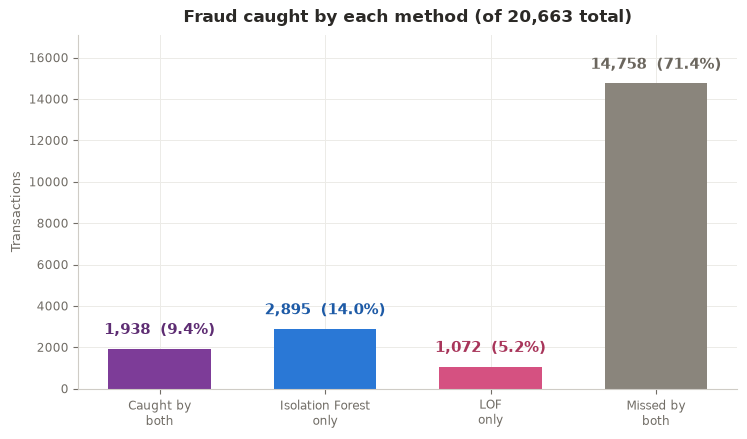

Caught by at least one method: 5,905
  of those, found by only one: 3,967 (67%)
Missed by both: 14,758 (71.4% of all fraud)


In [21]:
# Split every fraudulent transaction by which method flagged it
fraud_idx = np.where(y == 1)[0]
in_if = np.isin(fraud_idx, list(top_if))
in_lof = np.isin(fraud_idx, list(top_lof))

breakdown = pd.DataFrame([
    {'group': 'Caught by both', 'frauds': int((in_if & in_lof).sum())},
    {'group': 'Isolation Forest only', 'frauds': int((in_if & ~in_lof).sum())},
    {'group': 'LOF only', 'frauds': int((~in_if & in_lof).sum())},
    {'group': 'Missed by both', 'frauds': int((~in_if & ~in_lof).sum())},
])
breakdown['share_of_all_fraud_pct'] = (breakdown['frauds'] / N_FRAUD * 100).round(1)

# Save it for the report
breakdown.to_csv(os.path.join(RESULTS_DIR, 'catch_breakdown.csv'), index=False)
display(breakdown)

# Plot the four groups as separate bars
fig, ax = plt.subplots(figsize=(8.5, 4.6))

order = ['Caught by both', 'Isolation Forest only', 'LOF only', 'Missed by both']
plot_data = breakdown.set_index('group').loc[order]
colours = {'Caught by both': C_BOTH, 'Isolation Forest only': C_IF,
           'LOF only': C_LOF, 'Missed by both': C_NEITHER}
text_colours = {'Caught by both': C_BOTH_TEXT, 'Isolation Forest only': C_IF_TEXT,
                'LOF only': C_LOF_TEXT, 'Missed by both': C_NEITHER_TEXT}

bars = ax.bar(range(len(plot_data)), plot_data['frauds'],
              color=[colours[g] for g in plot_data.index], width=0.62)

# Count and share on ONE line above each bar
for bar, (group, row) in zip(bars, plot_data.iterrows()):
    ax.annotate(f"{int(row['frauds']):,}  ({row['share_of_all_fraud_pct']:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, row['frauds']),
                xytext=(0, 8), textcoords='offset points',
                ha='center', va='bottom', fontsize=10.5,
                color=text_colours[group], fontweight='bold')

# Label each bar with its group, wrapped onto two lines so the names fit
NEWLINE = chr(10)
ax.set_xticks(range(len(plot_data)))
ax.set_xticklabels([g.replace(' only', NEWLINE + 'only')
                     .replace('Caught by ', 'Caught by' + NEWLINE)
                     .replace('Missed by ', 'Missed by' + NEWLINE)
                    for g in plot_data.index], fontsize=9.5)

ax.set_ylim(0, plot_data['frauds'].max() * 1.16)
style_plot(ax, f'Fraud caught by each method (of {N_FRAUD:,} total)', None, 'Transactions')

save_fig(fig, 'catch_breakdown.png')
plt.show()

# Print
caught_by_any = int(breakdown.loc[breakdown['group'] != 'Missed by both', 'frauds'].sum())
only_one = int(breakdown.loc[breakdown['group'].isin(
    ['Isolation Forest only', 'LOF only']), 'frauds'].sum())
missed = int(breakdown.loc[breakdown['group'] == 'Missed by both', 'frauds'].iloc[0])
rho, _ = spearmanr(if_scores, lof_scores)
overlap = len(top_if & top_lof)

print(f"Caught by at least one method: {caught_by_any:,}")
print(f"  of those, found by only one: {only_one:,} ({only_one / caught_by_any * 100:.0f}%)")
print(f"Missed by both: {missed:,} ({missed / N_FRAUD * 100:.1f}% of all fraud)")

- **Comment:** Most of the fraud that is caught is found by only one of the two methods. That is the case for running both.


<a id="umap"></a>
<h1 style="color:#C2185B">VI. UMAP Projection</h1>

In [22]:
# Display the UMAP projection of the 50,000-row sample, coloured by each method's scores.
embedding_path = os.path.join(UMAP_DIR, 'umap_embedding.npy')
index_path = os.path.join(UMAP_DIR, 'umap_sample_index.npy')
have_map = os.path.exists(embedding_path) and os.path.exists(index_path)

if not have_map:
    print("No saved projection found. Run 00_nafisat/notebooks/07-umap-maps.ipynb first.")
else:
    embedding = np.load(embedding_path)
    sample_idx = np.load(index_path)

    # Take the label and the flags for the sampled rows only
    y_sample = y[sample_idx]
    fraud_sample = y_sample == 1
    flag_if_sample = np.isin(sample_idx, list(top_if))
    flag_lof_sample = np.isin(sample_idx, list(top_lof))

    # Print
    print(f"Projection: {len(embedding):,} transactions")
    print(f"Fraud in the projection: {int(fraud_sample.sum()):,} "
          f"({fraud_sample.mean() * 100:.2f}%)")


Projection: 50,000 transactions
Fraud in the projection: 1,787 (3.57%)


In [23]:
# Helpers for the maps below, so all three are drawn the same way
MAP_BACKGROUND = '#faf9f7'


# Define function to frame a map
def map_frame(ax, title=None, subtitle=None):
    """Frame a map. No tick marks, because UMAP coordinates have no units."""
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_facecolor(MAP_BACKGROUND)
    for side in ('top', 'right', 'bottom', 'left'):
        ax.spines[side].set_color('#d9d5cd')
        ax.spines[side].set_linewidth(0.9)
    if title:
        # Generous padding, so the title and the line under it are not crowded
        ax.set_title(title, fontsize=13, fontweight='bold', color=C_INK,
                     pad=30 if subtitle else 12)
    if subtitle:
        ax.text(0.5, 1.022, subtitle, transform=ax.transAxes, ha='center',
                va='bottom', fontsize=9.5, color=C_SOFT)
    return ax


# Define function to draw every transaction faintly behind the coloured points
def draw_backdrop(ax, coords):
    """Draw every transaction as a faint grey field."""
    ax.scatter(coords[:, 0], coords[:, 1], s=2.5, c='#dcd8d0',
               alpha=0.30, linewidths=0, rasterized=True)


# Print
print("Map helpers defined")

Map helpers defined


<a id="map-fraud"></a>
<h2 style="color:#C2185B">1. Fraud in the projection</h2>

Saved map_fraud.png


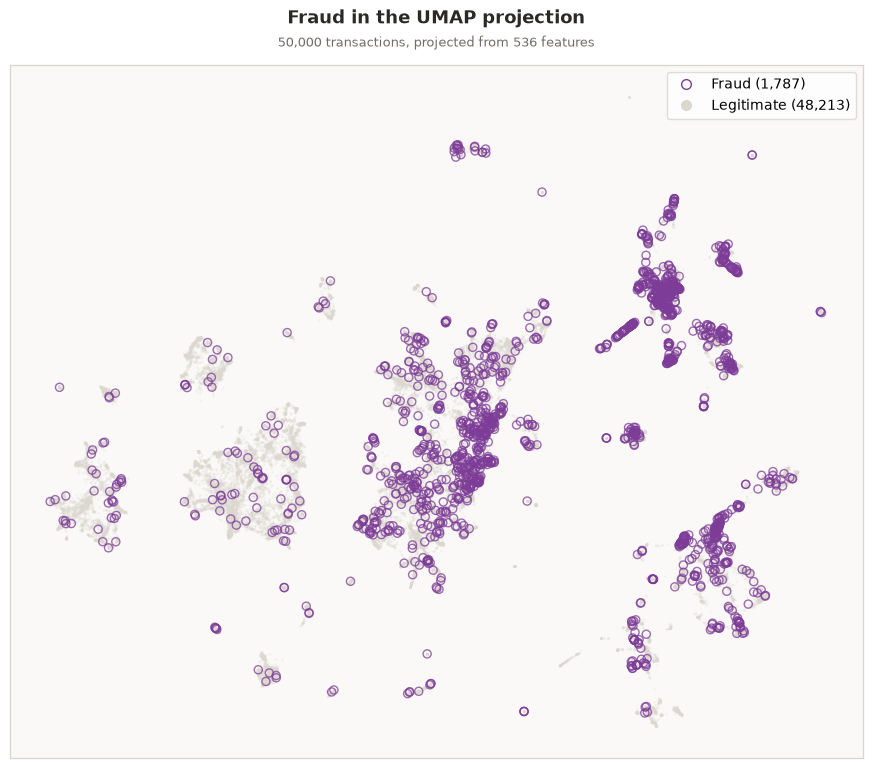

In [24]:
if have_map:
    fig, ax = plt.subplots(figsize=(11, 9))
    fig.patch.set_facecolor('white')

    # Every transaction as a faint backdrop
    draw_backdrop(ax, embedding)

    # Fraud as hollow rings, so overlapping cases stay countable
    ax.scatter(embedding[fraud_sample, 0], embedding[fraud_sample, 1],
               s=34, facecolor='none', edgecolor=C_BOTH, linewidths=1.0,
               alpha=0.75, rasterized=True)

    # Add a legend
    handles = [
        plt.Line2D([], [], marker='o', linestyle='none', markersize=7,
                   markerfacecolor='none', markeredgecolor=C_BOTH,
                   label=f'Fraud ({int(fraud_sample.sum()):,})'),
        plt.Line2D([], [], marker='o', linestyle='none', markersize=7,
                   color='#dcd8d0',
                   label=f'Legitimate ({int((~fraud_sample).sum()):,})'),
    ]
    leg = ax.legend(handles=handles, frameon=True, fontsize=10, loc='upper right')
    leg.get_frame().set_edgecolor('#d9d5cd')
    leg.get_frame().set_facecolor('white')

    map_frame(ax, 'Fraud in the UMAP projection',
              f'{len(embedding):,} transactions, projected from 536 features')

    save_fig(fig, 'map_fraud.png')
    plt.show()

<a id="map-flagged"></a>
<h2 style="color:#C2185B">2. What each method flagged</h2>

Saved map_flagged.png


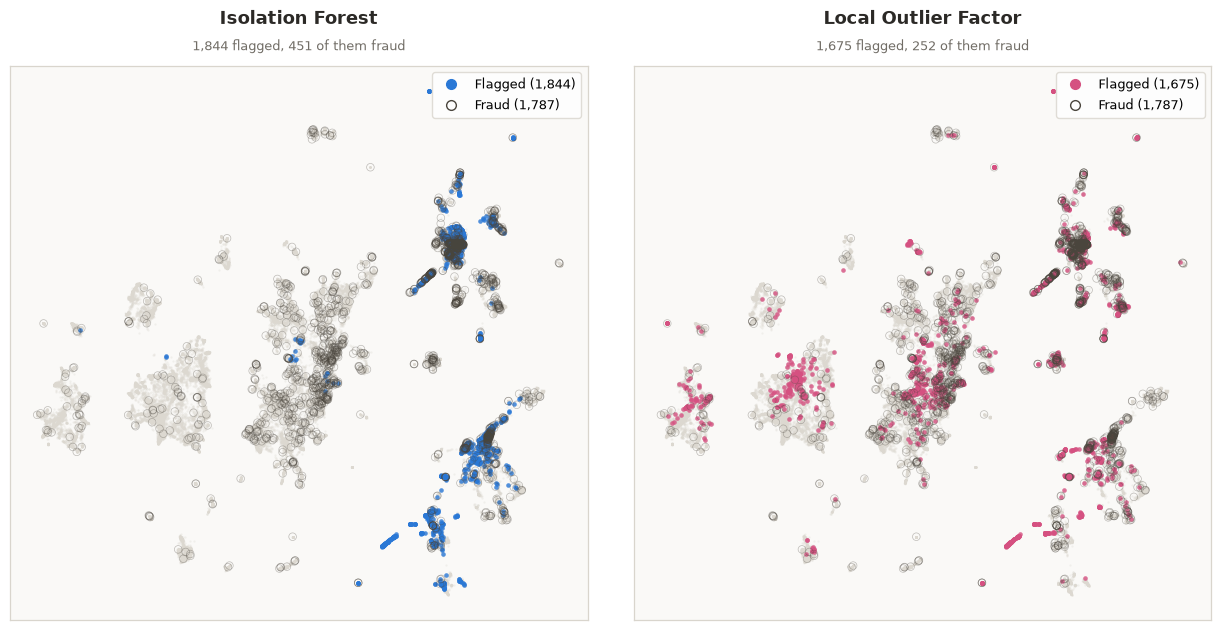

In [25]:
if have_map:
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 7.2), gridspec_kw={'wspace': 0.08})
    fig.patch.set_facecolor('white')

    for ax, flags, name, colour in [(axes[0], flag_if_sample, 'Isolation Forest', C_IF),
                                    (axes[1], flag_lof_sample, 'Local Outlier Factor', C_LOF)]:
        draw_backdrop(ax, embedding)

        # The transactions this method flagged
        ax.scatter(embedding[flags, 0], embedding[flags, 1], s=11, c=colour,
                   alpha=0.80, linewidths=0, rasterized=True)
        # Fraud as faint rings underneath, to show which flags landed on fraud
        ax.scatter(embedding[fraud_sample, 0], embedding[fraud_sample, 1], s=30,
                   facecolor='none', edgecolor='#4a453d', linewidths=0.5,
                   alpha=0.35, rasterized=True)

        hits = int((flags & fraud_sample).sum())

        handles = [
            plt.Line2D([], [], marker='o', linestyle='none', markersize=7,
                       color=colour, label=f'Flagged ({int(flags.sum()):,})'),
            plt.Line2D([], [], marker='o', linestyle='none', markersize=7,
                       markerfacecolor='none', markeredgecolor='#4a453d',
                       label=f'Fraud ({int(fraud_sample.sum()):,})'),
        ]
        leg = ax.legend(handles=handles, frameon=True, fontsize=9.5, loc='upper right')
        leg.get_frame().set_edgecolor('#d9d5cd')
        leg.get_frame().set_facecolor('white')

        map_frame(ax, name, f'{int(flags.sum()):,} flagged, {hits:,} of them fraud')

    save_fig(fig, 'map_flagged.png')
    plt.show()

<a id="map-caught"></a>
<h2 style="color:#C2185B">3. Fraud caught by each method</h2>

Saved map_catch_breakdown.png


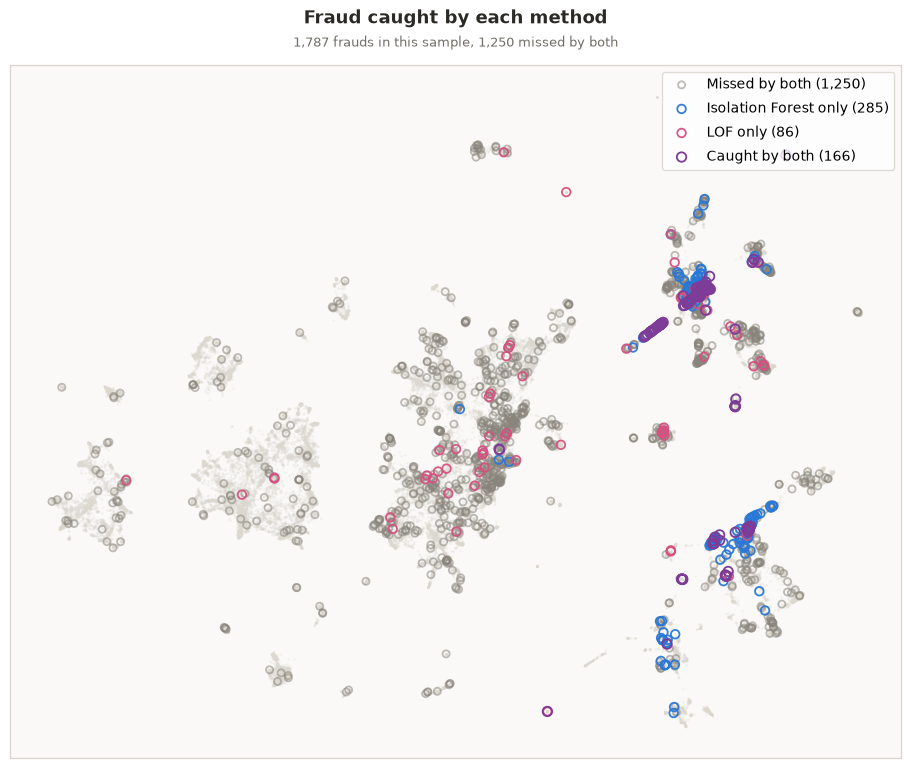

In [26]:
if have_map:
    # The same four groups as the table in V.5
    groups = [
        ('Missed by both', fraud_sample & ~flag_if_sample & ~flag_lof_sample, C_NEITHER, 26, 0.55),
        ('Isolation Forest only', fraud_sample & flag_if_sample & ~flag_lof_sample, C_IF, 38, 0.95),
        ('LOF only', fraud_sample & ~flag_if_sample & flag_lof_sample, C_LOF, 38, 0.95),
        ('Caught by both', fraud_sample & flag_if_sample & flag_lof_sample, C_BOTH, 46, 1.0),
    ]

    fig, ax = plt.subplots(figsize=(11.5, 9))
    fig.patch.set_facecolor('white')
    draw_backdrop(ax, embedding)

    # Missed fraud first and palest, caught fraud last and strongest
    for name, mask, colour, size, alpha in groups:
        ax.scatter(embedding[mask, 0], embedding[mask, 1], s=size,
                   facecolor='none', edgecolor=colour, linewidths=1.3,
                   alpha=alpha, rasterized=True,
                   label=f'{name} ({int(mask.sum()):,})')

    missed_sample = int(groups[0][1].sum())
    leg = ax.legend(frameon=True, fontsize=10, loc='upper right', labelspacing=0.7)
    leg.get_frame().set_edgecolor('#d9d5cd')
    leg.get_frame().set_facecolor('white')

    map_frame(ax, 'Fraud caught by each method',
              f'{int(fraud_sample.sum()):,} frauds in this sample, '
              f'{missed_sample:,} missed by both')

    save_fig(fig, 'map_catch_breakdown.png')
    plt.show()

- **Comment:** The map is a 50,000-row sample, because UMAP cannot lay out the full dataset in reasonable time. The scores colouring it were computed on every transaction.


<a id="runtime"></a>
<h1 style="color:#C2185B">VII. Runtime</h1>

Saved runtime.png


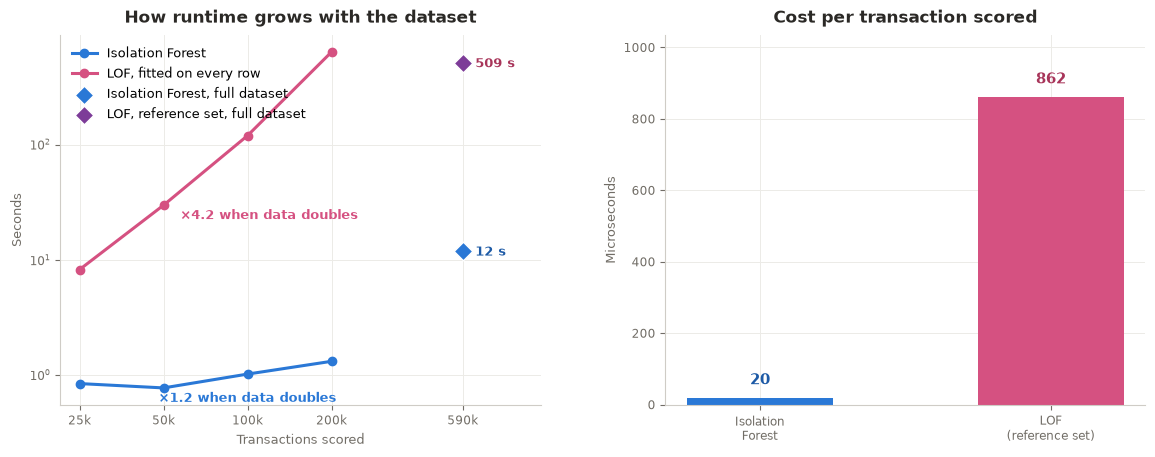

Isolation Forest: 11.8 s for 590,540 transactions (20 microseconds each)
LOF:              509.2 s for 590,540 transactions (862 microseconds each)
LOF costs 43 times more per transaction.


In [27]:
# What each method cost on the full dataset, and how that cost grows
if_seconds = float(if_final['runtime_seconds'])
lof_seconds = float(lof_final['runtime_seconds'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'wspace': 0.26})

# Left: how runtime grows with the dataset
TIMES = chr(215)  # the multiplication sign, not the letter x
exponents = {}
if os.path.exists(LADDER_PATH):
    ladder = pd.read_csv(LADDER_PATH)
    for column, name, colour in [('if_total_seconds', 'Isolation Forest', C_IF),
                                 ('lof_total_seconds', 'LOF, fitted on every row', C_LOF)]:
        if column in ladder.columns and ladder[column].notna().sum() >= 2:
            valid = ladder[ladder[column].notna()]
            # Fit a straight line through the log of both axes: the slope is
            # the power the runtime grows by
            exponent = np.polyfit(np.log(valid['n_rows']), np.log(valid[column]), 1)[0]
            exponents[name] = exponent
            # Say what the exponent means rather than printing it alone
            doubling = 2 ** exponent
            axes[0].plot(valid['n_rows'], valid[column], marker='o', linewidth=2.2,
                         color=colour, label=name)
            # The growth rate goes on the line itself rather than in the
            # legend, so the legend stays a list of names
            # Place each label in the empty space beside its own line. The
            # LOF line climbs steeply into the title and the legend, so its
            # label is anchored low on the line and pushed out to the right.
            is_if = column.startswith('if_')
            anchor = valid.iloc[-2] if is_if else valid.iloc[1]
            axes[0].annotate(f'{TIMES}{doubling:.1f} when data doubles',
                             xy=(anchor['n_rows'], anchor[column]),
                             xytext=(0, -20) if is_if else (12, -10),
                             textcoords='offset points',
                             ha='center' if is_if else 'left',
                             fontsize=9, color=colour, fontweight='bold')

    # Mark where each method actually ran on the full dataset as diamond
    axes[0].scatter([N_ROWS], [if_seconds], s=90, marker='D', color=C_IF,
                    zorder=5, edgecolor='white', linewidth=1,
                    label='Isolation Forest, full dataset')
    axes[0].scatter([N_ROWS], [lof_seconds], s=90, marker='D', color=C_BOTH,
                    zorder=5, edgecolor='white', linewidth=1,
                    label='LOF, reference set, full dataset')
    # Label each diamond with its runtime, which the legend no longer carries
    for seconds, colour in [(if_seconds, C_IF_TEXT), (lof_seconds, C_LOF_TEXT)]:
        axes[0].annotate(f'{seconds:.0f} s', xy=(N_ROWS, seconds),
                         xytext=(9, -3), textcoords='offset points',
                         fontsize=9, color=colour, fontweight='bold')

    axes[0].set_yscale('log')
    # Label the x-axis with the sizes actually run. Left to itself, a log axis
    # fills the gap between 200,000 and 590,540 with minor labels like 3x10^5
    # that overlap the majors, which is what squashed this axis.
    tested = sorted(set(valid['n_rows'].astype(int)) | {N_ROWS})
    axes[0].set_xscale('log')
    axes[0].set_xticks(tested)
    axes[0].set_xticklabels([f'{v // 1000}k' for v in tested], fontsize=9)
    axes[0].minorticks_off()
    # Room on the right for the two diamond labels
    axes[0].set_xlim(right=N_ROWS * 1.9)
    style_plot(axes[0], 'How runtime grows with the dataset',
               'Transactions scored', 'Seconds')
    axes[0].legend(frameon=False, fontsize=9, loc='upper left')

# Right: cost per transaction, side by side
per_row = [if_seconds / N_ROWS * 1e6, lof_seconds / N_ROWS * 1e6]
bars = axes[1].bar(['Isolation\nForest', 'LOF\n(reference set)'], per_row,
                   color=[C_IF, C_LOF], width=0.5)
for bar, value, colour in zip(bars, per_row, [C_IF_TEXT, C_LOF_TEXT]):
    axes[1].annotate(f'{value:,.0f}', xy=(bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 7), textcoords='offset points', ha='center',
                     va='bottom', fontsize=11, color=colour, fontweight='bold')
axes[1].set_ylim(0, max(per_row) * 1.2)
style_plot(axes[1], 'Cost per transaction scored', None, 'Microseconds')

save_fig(fig, 'runtime.png')
plt.show()

# Print, in plain words rather than exponents
ratio = max(per_row) / min(per_row)
print(f"Isolation Forest: {if_seconds:.1f} s for {N_ROWS:,} transactions "
      f"({per_row[0]:,.0f} microseconds each)")
print(f"LOF:              {lof_seconds:.1f} s for {N_ROWS:,} transactions "
      f"({per_row[1]:,.0f} microseconds each)")
print(f"LOF costs {ratio:.0f} times more per transaction.")


- **Comment:** Isolation Forest barely slows as the data grows, because each tree is built from a fixed number of rows. LOF fitted on every row compares each transaction against the others, so its cost grows faster than the data. A reference set avoids that.


<a id="research-questions"></a>
<h1 style="color:#C2185B">VIII. Research Questions</h1>

<a id="rq1"></a>
<h2 style="color:#C2185B">1. RQ1: detection without labels</h2>

Saved rq1_detection.png


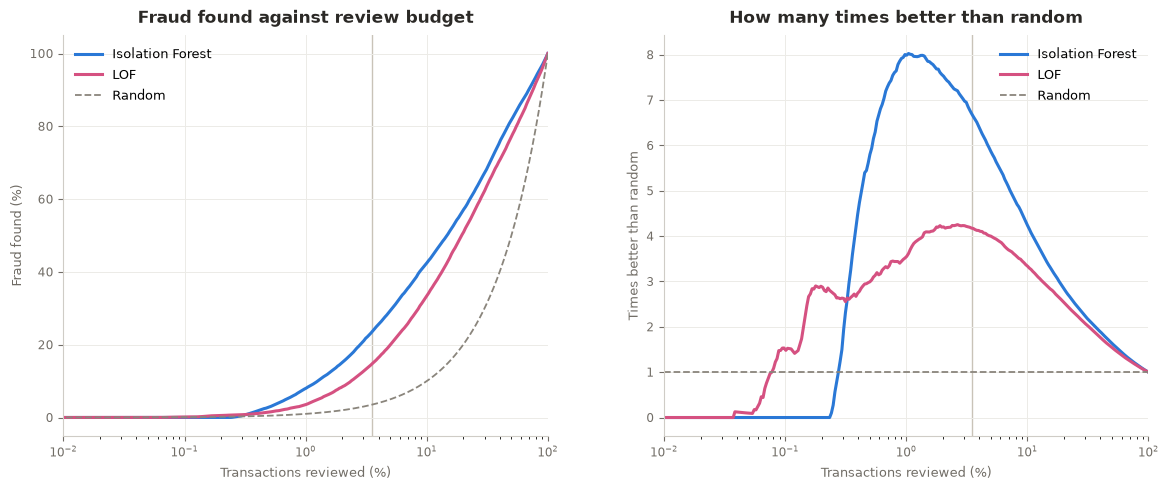

In [28]:
# Walk down each ranking and count the fraud found so far, against what random
# selection would find at the same depth
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'wspace': 0.24})

# Evaluate at points spread evenly on a log scale, so small budgets are visible
grid = np.unique(np.logspace(0, np.log10(N_ROWS), 400).astype(int))
grid = grid[grid >= 1]

for scores, name, colour in [(if_scores, 'Isolation Forest', C_IF),
                             (lof_scores, 'LOF', C_LOF)]:
    order = np.argsort(scores)[::-1]
    found = np.cumsum(y[order])
    ax.plot(grid / N_ROWS * 100, found[grid - 1] / N_FRAUD * 100,
            linewidth=2.2, color=colour, label=name)
    ax2.plot(grid / N_ROWS * 100, (found[grid - 1] / grid) / BASE_RATE,
             linewidth=2.2, color=colour, label=name)

# Random selection finds x% of the fraud after reviewing x% of the queue. It is
# traced across the grid: two endpoints would render flat on a log axis.
ax.plot(grid / N_ROWS * 100, grid / N_ROWS * 100, '--',
        color=C_NEITHER, linewidth=1.3, label='Random')
ax2.axhline(1.0, linestyle='--', color=C_NEITHER, linewidth=1.3, label='Random')

# Mark the review budget used elsewhere in the notebook
for a in (ax, ax2):
    a.axvline(REVIEW_BUDGET_FRAC * 100, color='#c9c3b8', linewidth=1, zorder=0)
    a.set_xscale('log')
    a.set_xlim(0.01, 100)

style_plot(ax, 'Fraud found against review budget',
           'Transactions reviewed (%)', 'Fraud found (%)')
style_plot(ax2, 'How many times better than random',
           'Transactions reviewed (%)', 'Times better than random')
ax.legend(frameon=False, fontsize=9.5)
ax2.legend(frameon=False, fontsize=9.5)

save_fig(fig, 'rq1_detection.png')
plt.show()


- **Comment:** The right panel is jumpy at very small budgets, where a single fraud moves the ratio a long way. It settles once the budget reaches the thousands.


<a id="rq2"></a>
<h2 style="color:#C2185B">2. RQ2: comparing the two methods</h2>

Saved rq2_comparison.png


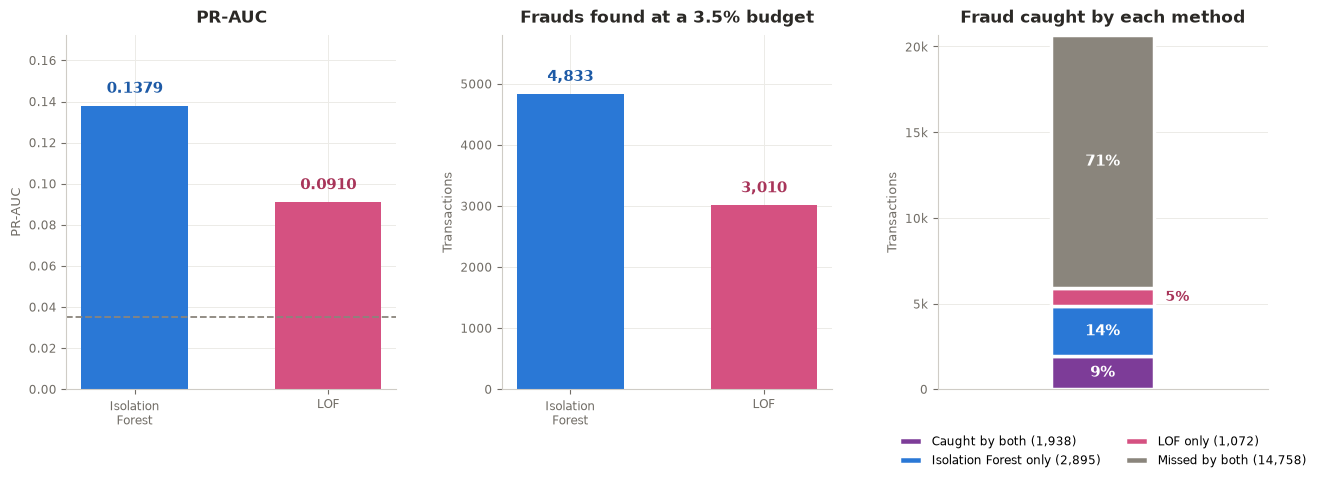

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.6), gridspec_kw={'wspace': 0.32})

names = ['Isolation\nForest', 'LOF']
colours_pair = [C_IF, C_LOF]
text_pair = [C_IF_TEXT, C_LOF_TEXT]

# Panel 1: ranking quality
values = [if_metrics['pr_auc'], lof_metrics['pr_auc']]
bars = axes[0].bar(names, values, color=colours_pair, width=0.55)
axes[0].axhline(BASE_RATE, linestyle='--', color=C_NEITHER, linewidth=1.3)
for bar, value, colour in zip(bars, values, text_pair):
    axes[0].annotate(f'{value:.4f}', xy=(bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 7), textcoords='offset points', ha='center',
                     va='bottom', fontsize=10.5, color=colour, fontweight='bold')
axes[0].set_ylim(0, max(values) * 1.25)
style_plot(axes[0], 'PR-AUC', None, 'PR-AUC')

# Panel 2: fraud found at the same budget
found = [if_metrics['frauds_found'], lof_metrics['frauds_found']]
bars = axes[1].bar(names, found, color=colours_pair, width=0.55)
for bar, value, colour in zip(bars, found, text_pair):
    axes[1].annotate(f'{value:,}', xy=(bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 7), textcoords='offset points', ha='center',
                     va='bottom', fontsize=10.5, color=colour, fontweight='bold')
axes[1].set_ylim(0, max(found) * 1.2)
style_plot(axes[1], f'Frauds found at a {REVIEW_BUDGET_FRAC:.1%} budget',
           None, 'Transactions')

# Panel 3: which method caught which fraud, as one horizontal bar
# One vertical bar holding all 20,663 frauds, split by who caught them.
# Stacked rather than four separate bars, so the missed share is seen as a
# part of the whole instead of as a column standing on its own.
bottom = 0
for _, r in breakdown.iterrows():
    axes[2].bar([0], [r['frauds']], bottom=bottom, width=0.5,
                color=colours[r['group']], edgecolor='white', linewidth=2.5,
                label=f"{r['group']} ({r['frauds']:,})")
    # Every segment gets its percentage, including the thin ones. A segment
    # shorter than 8% of the bar has no room for text inside it, so that
    # label goes outside to the right, in the segment's own colour so it
    # stays obvious which slice it belongs to.
    share = r['share_of_all_fraud_pct']
    middle = bottom + r['frauds'] / 2
    if r['frauds'] / N_FRAUD > 0.08:
        axes[2].text(0, middle, f"{share:.0f}%", ha='center', va='center',
                     fontsize=11, color='white', fontweight='bold')
    else:
        axes[2].annotate(f"{share:.0f}%", xy=(0.25, middle),
                         xytext=(8, 0), textcoords='offset points',
                         ha='left', va='center', fontsize=10,
                         color=text_colours[r['group']], fontweight='bold')
    bottom += r['frauds']

axes[2].set_xticks([])
# Symmetric limits, so the bar sits in the middle of the panel. The span is
# wide enough that a label placed outside the bar still has room.
axes[2].set_xlim(-0.8, 0.8)
axes[2].set_ylim(0, N_FRAUD)
# Fixed ticks in thousands, so the axis does not print 10000, 12500 and 15000
# hard against each other on a panel this narrow
ticks = list(range(0, N_FRAUD + 1, 5_000))
axes[2].set_yticks(ticks)
axes[2].set_yticklabels([f'{t // 1000}k' if t else '0' for t in ticks], fontsize=9)
style_plot(axes[2], 'Fraud caught by each method', None, 'Transactions')
axes[2].legend(frameon=False, fontsize=8.5, loc='upper center',
               bbox_to_anchor=(0.5, -0.1), ncol=2)

save_fig(fig, 'rq2_comparison.png')
plt.show()

- **Comment:** Isolation Forest wins on quality and on cost. LOF earns its place by finding fraud the forest misses.


<a id="rq3"></a>
<h2 style="color:#C2185B">3. RQ3: computational cost</h2>

The runtime figure in section VII already answers this question.

<a id="limitations"></a>
<h1 style="color:#C2185B">IX. Limitations</h1>

1. No train/test split anywhere. Every number describes how well these methods separate this dataset.
2. Labels were used to choose hyperparameters, so the honest phrasing is *no labels during training*,
   never *fully unsupervised*.
3. Outliers are a proxy for fraud. Most fraud here is not an outlier at all.
4. One seed per configuration. PR-AUC moves by a few thousandths between seeds.
5. LOF's `n_neighbors` was chosen on a 25,000-row sample and applied to a 50,000-row reference set.

In [30]:
# Print the figures behind the limitations above
print(f"Evaluated on {N_ROWS:,} transactions, {N_FRAUD:,} fraud, with no held-out set")
print(f"Fraud missed by both methods: {missed:,} ({missed / N_FRAUD * 100:.1f}%)")

# Compare each method's tuned result against its untuned default
for name, log in [('Isolation Forest', if_log), ('LOF', lof_full_log)]:
    base = log[log['experiment'] == 'baseline']
    final = log[log['experiment'] == 'final']
    if len(base) and len(final):
        b, f = base.iloc[-1]['pr_auc'], final.iloc[-1]['pr_auc']
        print(f"{name}: untuned {b:.4f}, tuned {f:.4f} ({(f - b) / b * 100:+.1f}%)")

Evaluated on 590,540 transactions, 20,663 fraud, with no held-out set
Fraud missed by both methods: 14,758 (71.4%)
Isolation Forest: untuned 0.1352, tuned 0.1379 (+2.0%)
LOF: untuned 0.0622, tuned 0.0910 (+46.1%)


<a id="sanity-check"></a>
<h1 style="color:#C2185B">X. Sanity Check</h1>

In [31]:
# 1. Both methods cover every transaction
assert len(if_scores) == len(lof_scores) == N_ROWS
print(f"1. Both methods scored the same {N_ROWS:,} transactions")

# 2. Each method's score here matches what its own notebook logged
for name, scores, final in [('Isolation Forest', if_scores, if_final),
                            ('LOF', lof_scores, lof_final)]:
    here = roc_auc_score(y, scores)
    logged = float(final['roc_auc'])
    assert abs(here - logged) < 0.001, f"{name}: {here:.4f} here, {logged:.4f} logged"
    print(f"2. {name}: ROC-AUC {here:.4f} matches its log")

# 3. The four catch groups account for every fraud exactly once
assert int(breakdown['frauds'].sum()) == N_FRAUD
print(f"3. The catch groups sum to all {N_FRAUD:,} frauds")

# 4. The sweep tables and the full-data tables describe different row counts,
#    which is the distinction section IV keeps separate
assert int(lof_full_table['rows_scored'].iloc[0]) == N_ROWS
print(f"4. LOF's full-data runs cover {N_ROWS:,} rows, its sweep {LOF_SWEEP_ROWS:,}")

# 5. Every table was written to disk
expected = ['if_baseline_and_final.csv', 'if_n_estimators.csv', 'if_max_samples.csv',
            'if_contamination.csv', 'lof_sample_sweep.csv', 'lof_full_runs.csv',
            'final_models_comparison.csv', 'review_budget.csv', 'catch_breakdown.csv']
written = [f for f in expected if os.path.exists(os.path.join(RESULTS_DIR, f))]
assert len(written) == len(expected), f"missing: {sorted(set(expected) - set(written))}"
print(f"5. All {len(expected)} tables written to {RESULTS_DIR}")

print()
print("All checks passed")

1. Both methods scored the same 590,540 transactions
2. Isolation Forest: ROC-AUC 0.7568 matches its log
2. LOF: ROC-AUC 0.7134 matches its log
3. The catch groups sum to all 20,663 frauds
4. LOF's full-data runs cover 590,540 rows, its sweep 25,000
5. All 9 tables written to c:\Users\Nafis\ProjectsHub_WiM\unsupervised-fraud-detection-the-outliers\results\final_evaluation

All checks passed


<a id="appendix"></a>
<h1 style="color:#C2185B">Appendix: Combining the Two Rankings</h1>

Isolation Forest and LOF disagree about most of what they flag, which raises the question of whether using
both finds more fraud than either one alone.

**How it works.** The two scores cannot be added together: Isolation Forest's run from about 0.3 to 0.7
and LOF's from about 1 to 62, so adding them would let LOF decide every case. Instead each score is
converted to a **percentile**, a number from 0 to 1 saying what share of transactions it is more anomalous
than. A transaction at 0.99 is more anomalous than 99% of all transactions, and that means the same thing
for both methods. The two percentiles are then averaged, and the top 3.5% of the averaged ranking is
reviewed.

**Why it helps.** Each method on its own only ever opens its own most extreme cases. A transaction sitting
just below both cut-offs, fairly unusual by both measures without being extreme by either, is reviewed by
neither. Averaging pulls those cases into the budget.

This is an extension rather than part of the three research questions, which is why it sits here.

In [32]:
# Convert each score to a percentile rank, then average the two
rank_if = pd.Series(if_scores).rank(pct=True).to_numpy()
rank_lof = pd.Series(lof_scores).rank(pct=True).to_numpy()
avg_rank = (rank_if + rank_lof) / 2
avg_metrics = metrics_for(avg_rank, y)

# The intersection: flag only what both methods put in their top 3.5%
intersection = sorted(top_if & top_lof)
intersection_caught = int(y[intersection].sum())

# Put the two methods and the two ways of combining them in one table
ensemble = pd.DataFrame([
    {'approach': 'Isolation Forest', 'pr_auc': round(if_metrics['pr_auc'], 4),
     'reviewed': if_metrics['reviewed'], 'frauds_found': if_metrics['frauds_found'],
     'precision_pct': round(if_metrics['precision'] * 100, 2),
     'recall_pct': round(if_metrics['recall'] * 100, 2)},
    {'approach': 'LOF', 'pr_auc': round(lof_metrics['pr_auc'], 4),
     'reviewed': lof_metrics['reviewed'], 'frauds_found': lof_metrics['frauds_found'],
     'precision_pct': round(lof_metrics['precision'] * 100, 2),
     'recall_pct': round(lof_metrics['recall'] * 100, 2)},
    {'approach': 'Average rank', 'pr_auc': round(avg_metrics['pr_auc'], 4),
     'reviewed': avg_metrics['reviewed'], 'frauds_found': avg_metrics['frauds_found'],
     'precision_pct': round(avg_metrics['precision'] * 100, 2),
     'recall_pct': round(avg_metrics['recall'] * 100, 2)},
    # The intersection is a set, not a ranking, so it has no PR-AUC
    {'approach': 'Both agree', 'pr_auc': np.nan,
     'reviewed': len(intersection), 'frauds_found': intersection_caught,
     'precision_pct': round(intersection_caught / len(intersection) * 100, 2),
     'recall_pct': round(intersection_caught / N_FRAUD * 100, 2)},
]).set_index('approach')

# Save it for the report
ensemble.to_csv(os.path.join(RESULTS_DIR, 'ensemble_comparison.csv'))
display(ensemble)

,pr_auc,reviewed,frauds_found,precision_pct,recall_pct
approach,,,,,
Isolation Forest,0.1379,20668,4833,23.38,23.39
LOF,0.0910,20668,3010,14.56,14.57
Average rank,0.1589,20668,5600,27.10,27.10
Both agree,NaN,5954,1938,32.55,9.38


Saved ensemble_comparison.png


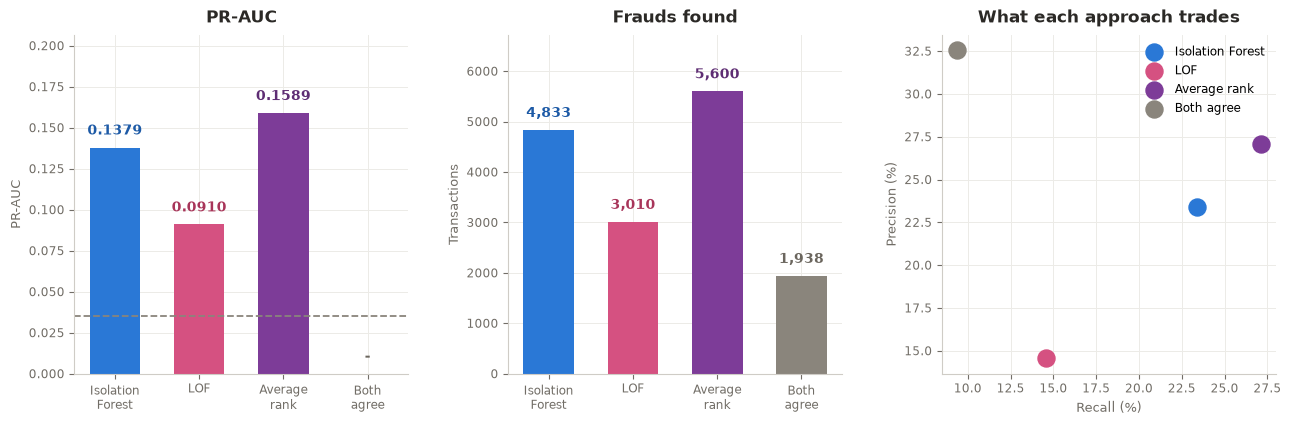

Average rank: PR-AUC 0.1589 against the best single method's 0.1379 (+15.2%)
At the same budget it finds 767 more frauds
Both agree: reviews 5,954 transactions, not 20,668, at 32.5% precision and 9.4% recall.


In [33]:
# The same four approaches, drawn
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.4), gridspec_kw={'wspace': 0.3})

approaches = ensemble.index.tolist()
bar_colours = [C_IF, C_LOF, C_BOTH, C_NEITHER]
bar_text = [C_IF_TEXT, C_LOF_TEXT, C_BOTH_TEXT, C_NEITHER_TEXT]
short = [a.replace(' ', chr(10)) for a in approaches]

# Panel 1: ranking quality. The intersection has no PR-AUC, so its bar is empty.
pr_values = ensemble['pr_auc'].fillna(0).tolist()
bars = axes[0].bar(short, pr_values, color=bar_colours, width=0.6)
axes[0].axhline(BASE_RATE, linestyle='--', color=C_NEITHER, linewidth=1.3)
for bar, value, colour in zip(bars, ensemble['pr_auc'].tolist(), bar_text):
    text = '-' if pd.isna(value) else f'{value:.4f}'
    axes[0].annotate(text, xy=(bar.get_x() + bar.get_width() / 2, 0 if pd.isna(value) else value),
                     xytext=(0, 7), textcoords='offset points', ha='center',
                     va='bottom', fontsize=10, color=colour, fontweight='bold')
axes[0].set_ylim(0, max(pr_values) * 1.3)
style_plot(axes[0], 'PR-AUC', None, 'PR-AUC')

# Panel 2: how much fraud each one finds
bars = axes[1].bar(short, ensemble['frauds_found'], color=bar_colours, width=0.6)
for bar, value, colour in zip(bars, ensemble['frauds_found'], bar_text):
    axes[1].annotate(f'{int(value):,}', xy=(bar.get_x() + bar.get_width() / 2, value),
                     xytext=(0, 7), textcoords='offset points', ha='center',
                     va='bottom', fontsize=10, color=colour, fontweight='bold')
axes[1].set_ylim(0, ensemble['frauds_found'].max() * 1.2)
style_plot(axes[1], 'Frauds found', None, 'Transactions')

# Panel 3: precision against recall, which is the trade each one makes
for approach, colour in zip(approaches, bar_colours):
    row = ensemble.loc[approach]
    axes[2].scatter(row['recall_pct'], row['precision_pct'], s=150,
                    color=colour, zorder=5, label=approach)
style_plot(axes[2], 'What each approach trades', 'Recall (%)', 'Precision (%)')
axes[2].legend(frameon=False, fontsize=8.5)

save_fig(fig, 'ensemble_comparison.png')
plt.show()

# Print
best_single = max(if_metrics['pr_auc'], lof_metrics['pr_auc'])
gain = (avg_metrics['pr_auc'] - best_single) / best_single * 100
extra = avg_metrics['frauds_found'] - max(if_metrics['frauds_found'],
                                          lof_metrics['frauds_found'])
print(f"Average rank: PR-AUC {avg_metrics['pr_auc']:.4f} against the best single "
      f"method's {best_single:.4f} ({gain:+.1f}%)")
print(f"At the same budget it finds {extra:,} more frauds")
print(f"Both agree: reviews {len(intersection):,} transactions, not {REVIEW_BUDGET:,}, "
      f"at {intersection_caught / len(intersection) * 100:.1f}% precision and "
      f"{intersection_caught / N_FRAUD * 100:.1f}% recall.")


- **Comment:** Averaging the two rankings beats either one alone. Requiring both to agree raises precision and drops recall.
